✅ Simulation 01 completed successfully!
📁 High-resolution figure saved at: figures/sim01_classical_limit_field_dynamics.png


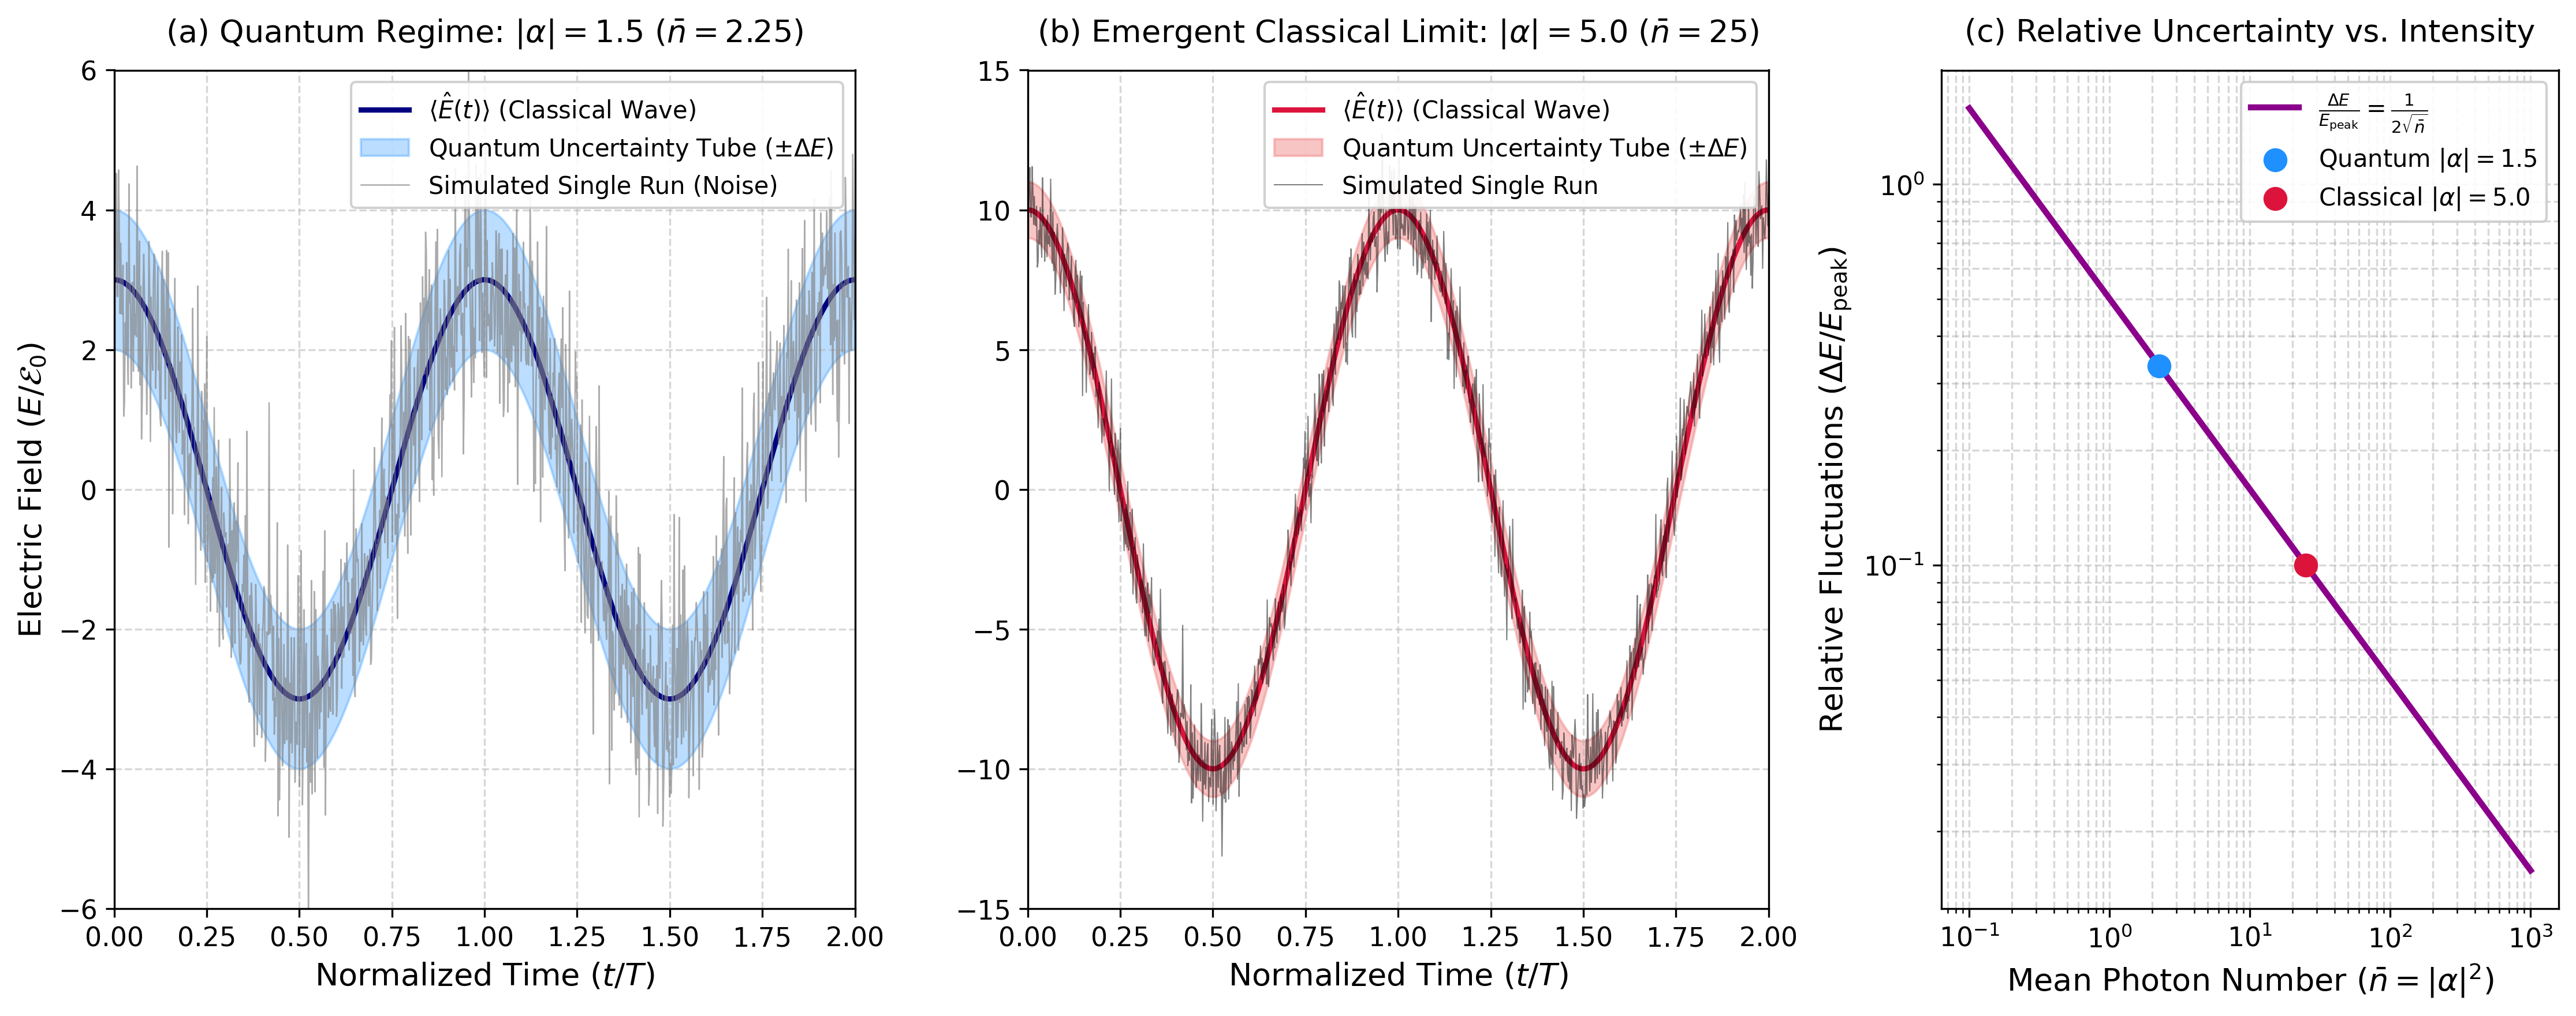

In [1]:
"""
===============================================================================
Computational Quantum Optics: Gerry & Knight Simulations
Chapter 03: Coherent States of Light
Simulation 01: Classical Limit & Electric Field Dynamics with Quantum Noise Tube
===============================================================================

Reference:
    "Introductory Quantum Optics", Christopher C. Gerry & Sir Peter L. Knight,
    Chapter 3, Sections 3.1 & 3.5.

Description:
    Demonstrates how classical sinusoidal electromagnetic waves emerge from 
    coherent states |alpha(t)>. Unlike Fock states (|n>) where <E(t)> = 0, a 
    coherent state exhibits a macroscopic oscillating electric field enveloped 
    by an irreducible, constant quantum uncertainty tube (delta E = E_0).
    Also simulates the transition to the classical Maxwellian regime as |alpha| -> inf.
"""

import os
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. Physics Parameters & Setup
# -----------------------------------------------------------------------------
# Set publication style aesthetics
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.titlesize': 15,
    'text.usetex': False  # Fully compatible with Kaggle and environments without LaTeX
})

# Physical Constants (Normalized units)
E0 = 1.0           # Electric field amplitude per photon (E0 = sqrt(hbar * omega / eps0 / V))
omega = 2.0 * np.pi  # Normalized optical frequency (1 full cycle per unit time)
T = 2.0 * np.pi / omega  # Optical period (T = 1.0)

# Time axis: simulate 2 complete optical cycles
t = np.linspace(0, 2.0 * T, 1000)

# Two coherent amplitudes to contrast Quantum vs. Semi-Classical regimes
alpha_quantum = 1.5   # Low-photon regime: n_bar = 2.25 (quantum noise dominant)
alpha_classic = 5.0   # Higher-photon regime: n_bar = 25.0 (classical wave dominant)

# Constant quantum field uncertainty for any coherent state
# Delta E = E0 * sqrt(2 * (Delta X1)^2 + 2 * (Delta X2)^2) = E0
delta_E = E0

# -----------------------------------------------------------------------------
# 2. Electric Field Dynamics & Simulated Measurement Trajectories
# -----------------------------------------------------------------------------
def get_field_dynamics(alpha_val, time_arr):
    """Calculates classical expectation value and simulated quantum measurements."""
    # Mean electric field: <E(t)> = 2 * E0 * |alpha| * cos(omega * t)
    mean_E = 2.0 * E0 * alpha_val * np.cos(omega * time_arr)
    
    # Generate a single stochastic quantum measurement run (Gaussian shot-noise)
    np.random.seed(42)  # For reproducible scientific visualization
    shot_noise = np.random.normal(0, delta_E, size=len(time_arr))
    trajectory = mean_E + shot_noise
    
    return mean_E, trajectory

mean_E_q, traj_q = get_field_dynamics(alpha_quantum, t)
mean_E_c, traj_c = get_field_dynamics(alpha_classic, t)

# -----------------------------------------------------------------------------
# 3. Classical Limit Analysis (Noise-to-Signal Ratio vs. Mean Photon Number)
# -----------------------------------------------------------------------------
n_bar_range = np.logspace(-1, 3, 500)  # From n_bar = 0.1 to 1000 photons
peak_field = 2.0 * E0 * np.sqrt(n_bar_range)
relative_uncertainty = delta_E / peak_field  # Delta E / E_peak = 1 / (2 * sqrt(n_bar))

# -----------------------------------------------------------------------------
# 4. Multi-Panel Figure Generation
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(15, 6), dpi=300)
gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.2, 1.0])

# --- Subplot (a): Quantum Dominant Regime (|alpha| = 1.5) ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(t / T, mean_E_q, color='navy', lw=2.2, label=r'$\langle \hat{E}(t) \rangle$ (Classical Wave)')
ax1.fill_between(t / T, mean_E_q - delta_E, mean_E_q + delta_E, 
                 color='dodgerblue', alpha=0.3, label=r'Quantum Uncertainty Tube ($\pm \Delta E$)')
ax1.plot(t / T, traj_q, color='gray', lw=0.6, alpha=0.65, label=r'Simulated Single Run (Noise)')

ax1.set_title(r'(a) Quantum Regime: $|\alpha| = 1.5$ ($\bar{n} = 2.25$)', pad=12)
ax1.set_xlabel(r'Normalized Time ($t / T$)')
ax1.set_ylabel(r'Electric Field ($E / \mathcal{E}_0$)')
ax1.set_xlim([0, 2])
ax1.set_ylim([-6, 6])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', frameon=True, framealpha=0.9)

# --- Subplot (b): Semi-Classical Regime (|alpha| = 5.0) ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(t / T, mean_E_c, color='crimson', lw=2.2, label=r'$\langle \hat{E}(t) \rangle$ (Classical Wave)')
ax2.fill_between(t / T, mean_E_c - delta_E, mean_E_c + delta_E, 
                 color='lightcoral', alpha=0.45, label=r'Quantum Uncertainty Tube ($\pm \Delta E$)')
ax2.plot(t / T, traj_c, color='black', lw=0.5, alpha=0.5, label=r'Simulated Single Run')

ax2.set_title(r'(b) Emergent Classical Limit: $|\alpha| = 5.0$ ($\bar{n} = 25$)', pad=12)
ax2.set_xlabel(r'Normalized Time ($t / T$)')
ax2.set_xlim([0, 2])
ax2.set_ylim([-15, 15])
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', frameon=True, framealpha=0.9)

# --- Subplot (c): Classical Limit Scaling (Noise-to-Signal Ratio) ---
ax3 = fig.add_subplot(gs[0, 2])
ax3.loglog(n_bar_range, relative_uncertainty, color='darkmagenta', lw=2.5, 
           label=r'$\frac{\Delta E}{E_{\mathrm{peak}}} = \frac{1}{2\sqrt{\bar{n}}}$')

# Highlight our two simulation points
ax3.scatter([alpha_quantum**2], [delta_E / (2 * E0 * alpha_quantum)], 
            color='dodgerblue', s=80, zorder=5, label=r'Quantum $|\alpha|=1.5$')
ax3.scatter([alpha_classic**2], [delta_E / (2 * E0 * alpha_classic)], 
            color='crimson', s=80, zorder=5, label=r'Classical $|\alpha|=5.0$')

ax3.set_title(r'(c) Relative Uncertainty vs. Intensity', pad=12)
ax3.set_xlabel(r'Mean Photon Number ($\bar{n} = |\alpha|^2$)')
ax3.set_ylabel(r'Relative Fluctuations ($\Delta E / E_{\mathrm{peak}}$)')
ax3.grid(True, which='both', linestyle='--', alpha=0.5)
ax3.legend(loc='upper right', frameon=True, framealpha=0.9)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 5. Export Figure
# -----------------------------------------------------------------------------
os.makedirs("figures", exist_ok=True)
output_path = os.path.join("figures", "sim01_classical_limit_field_dynamics.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"✅ Simulation 01 completed successfully!")
print(f"📁 High-resolution figure saved at: {output_path}")

plt.show()